# ***Crop Recommendation System ..***

It is data set which help farmers make information  decision and farming techniques.


This dataset is designed for Precision Agriculture.



Precision Agriculture helps farmers make informed farming decisions.

It is to recommend the most suitable crop.



Crop recommendations are based on soil and climate conditions.



The dataset can be used to build a Machine Learning model.



It combines rainfall, climate, and fertilizer data.


The dataset contains 2,200 records.







It includes 22 different crop types.



Each crop has 100 samples, making the dataset perfectly balanced.





#Description of each an every feature in this project--

N - Nitrogen

p - phosphorous

k - potassium

Temperature which measured degree or Celsius

humidity it is in %

ph value

Rainfall

label (Target) - the type of crops



In [25]:
#1. Import Libraries
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import matplotlib.patches as mpatches

import seaborn as sns

import joblib

In [26]:
#for ml modules
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold

from sklearn.preprocessing import MinMaxScaler, LabelEncoder

from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

from sklearn.svm import SVC

from xgboost import XGBClassifier

from sklearn.metrics import (accuracy_score, classification_report,confusion_matrix, precision_score,recall_score, f1_score)

In [27]:
#upload the data set
df = pd.read_csv('Crop_recommendation.csv')

Understand the data set


In [24]:
#total column
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [29]:
df.tail()

,N,P,K,temperature,humidity,ph,rainfall,label
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee


In [30]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


DATA QUALITY


In [31]:
df.isnull().sum()#missing value

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [32]:
df.duplicated().sum()#dulpicate value

np.int64(0)

In [8]:
#incorrect data
df.dtypes


,0
N,int64
P,int64
K,int64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,object


EDA & Visualization


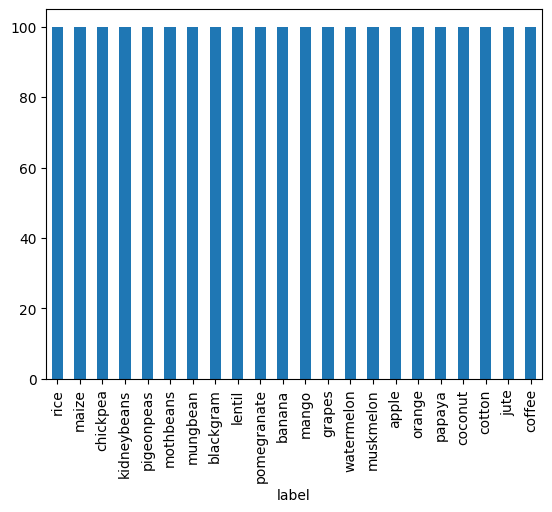

In [11]:
# 1. Bar Chart
df['label'].value_counts().plot(kind='bar')
plt.show()

here the graph is show  the number of samples for each crop.
 Every crop has 100 samples, indicating a balanced dataset.

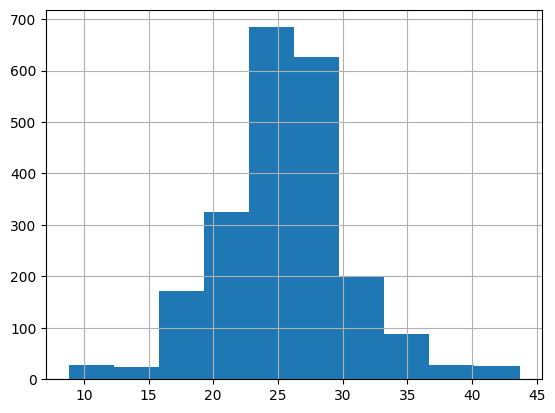

In [12]:
# 2. Histogram
df['temperature'].hist()
plt.show()

here the ghraph describe the distribution of temperature values.
 Most temperatures are concentrated around 25–30°C.

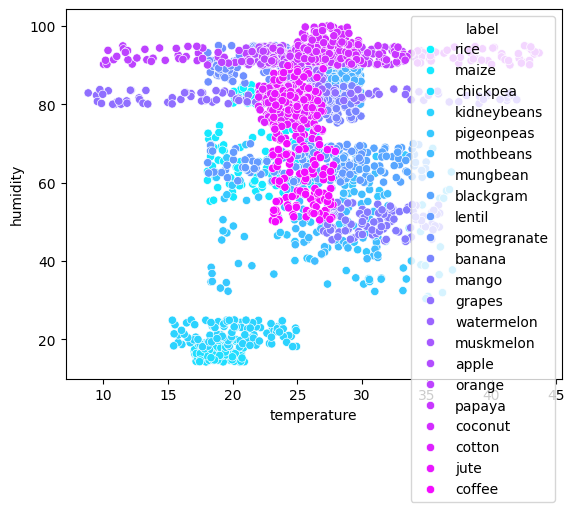

In [15]:
# 3. Scatter Plot
sns.scatterplot(x='temperature', y='humidity', hue='label', data=df,palette='cool')
plt.show()

Here in the using 'cool' for understand
 the relationship between temperature and humidity.

  Different colours represent different crop types

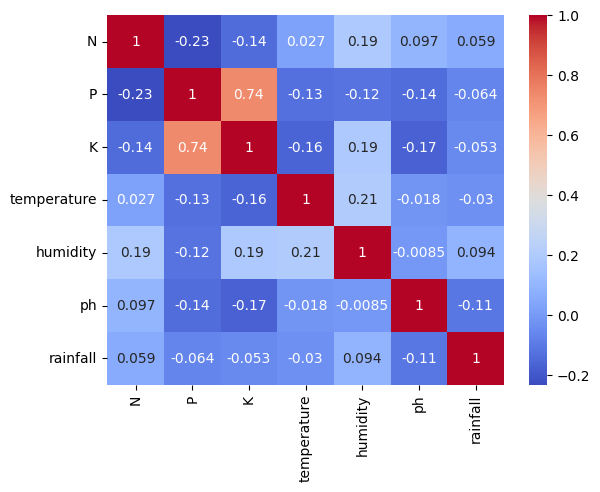

In [16]:
# 4. Correlation Heatmap
sns.heatmap(df.select_dtypes('number').corr(), annot=True, cmap='coolwarm')
plt.show()

 this graph shows the" correlation" between numerical features such as-- N, P, K, temperature, humidity, pH, and rainfall

this is the "Classification Model"

MODEL EVALUAION


In [21]:
# Split features and target

X = df.drop('label', axis=1)

y = df['label']

In [22]:
# Split training and testing data

X_train, X_test, y_train, y_test = train_test_split(  X, y, test_size=0.2, random_state=42, stratify=y
)

In [34]:
# Initialize and Train model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [36]:
# Check accuracy
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9954545454545455


In [37]:
# Classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

 Features: Includes Nitrogen (N), Phosphorus (P), Potassium (K), temperature, humidity, pH, and rainfall.

22 Crop Classes: Predicts different crops such as rice, maize, apple, banana, cotton, and others.

High Accuracy: Random Forest achieves approximately 99.55% accuracy.

This   will application helps farmers select suitable crops based on soil and weather conditions.

It supports ML classification, prediction, and data visualization.

**CONCLUTION**:-
# Learning: Learned data analysis, data visualization, and classification using Machine Learning.



#Result: Developed a model to recommend suitable crops based on soil and climate conditions.



#Limitations: Model performance depends on dataset quality and available features.





#Future Improvements: Add more real-world data and use advanced ML algorithms to improve predictions